# Task 2: Autoformer forecast of a 168-step horizon

In [1]:
import os, time, math, json, random, hashlib, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, signal
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import STL
from sklearn.feature_selection import mutual_info_regression
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 300)
SMOKE = False
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

OUT, RES, FIG = "final", os.path.join("final", "results"), os.path.join("final", "figures")
for d in (OUT, RES, FIG):
    os.makedirs(d, exist_ok=True)
_fn = [0]
def savefig(name):
    _fn[0] += 1
    p = os.path.join(FIG, f"fig{_fn[0]:02d}_{name}.pdf")
    plt.tight_layout(); plt.savefig(p, bbox_inches="tight"); plt.show(); plt.close(); print("saved", p)

In [2]:
DATA_DIR = os.environ.get("DATA_DIR", "/content/data")
FILES = ["student_train.csv", "student_test.csv", "optional_external_data.csv"]
if not all(os.path.exists(os.path.join(DATA_DIR, f)) for f in FILES):
    from google.colab import files as colab_files
    os.makedirs(DATA_DIR, exist_ok=True)

    for name, content in colab_files.upload().items():
        clean = name.split(" (")[0] + ".csv" if " (" in name else name
        open(os.path.join(DATA_DIR, clean), "wb").write(content)

train_df = pd.read_csv(os.path.join(DATA_DIR, "student_train.csv")).sort_values("time_idx")
test_df = pd.read_csv(os.path.join(DATA_DIR, "student_test.csv"))
ext = pd.read_csv(os.path.join(DATA_DIR, "optional_external_data.csv")).sort_values("time_idx").reset_index(drop=True)
y = train_df["value"].to_numpy(float)
N, H = len(y), 168
NT = N + H
assert N == 43656 and len(ext) == NT and (test_df.time_idx.to_numpy() == np.arange(N + 1, NT + 1)).all()
X = {c.replace("feature_", ""): ext[c].to_numpy(float) for c in ext.columns if c.startswith("feature_")}
BIN = [k for k, v in X.items() if set(np.unique(v)) <= {0, 1}]
CONT = [k for k in X if k not in BIN]
assert (np.sum([X[k] for k in BIN], 0) == 1).all()
print("continuous columns:", CONT, "| binary one-hot columns:", BIN)

N_VAL, N_ES = 52, 24
VAL_ORIGINS = np.array([N - H * k for k in range(N_VAL, 0, -1)])
V0 = int(VAL_ORIGINS[0])
ES_ORIGINS = np.array([V0 - H * k for k in range(N_ES, 0, -1)])
TRAIN_END = int(ES_ORIGINS[0])
ly = np.log1p(y)
print(f"fit [0,{TRAIN_END}) | early stopping [{TRAIN_END},{V0}) | validation [{V0},{N}) | test [{N},{NT})")

Saving optional_external_data.csv to optional_external_data.csv
Saving student_test.csv to student_test.csv
Saving student_train.csv to student_train.csv
continuous columns: ['A', 'B', 'C', 'D', 'E', 'F'] | binary one-hot columns: ['G', 'H', 'I', 'J']
fit [0,30888) | early stopping [30888,34920) | validation [34920,43656) | test [43656,43824)


In [3]:
P_SHORT, P_LONG = 24, 8766

statistic                          scope    ε²     p
     mean                between regions 0.021 0.235
     mean   within region 0: across bins 0.010 0.778
     mean within region 0: across cycles 0.247 0.006
     mean   within region 1: across bins 0.182 0.010
     mean within region 1: across cycles 0.022 0.766
     mean   within region 2: across bins 0.006 0.856
     mean within region 2: across cycles 0.238 0.007
     mean   within region 3: across bins 0.031 0.458
     mean within region 3: across cycles 0.035 0.622
 variance                between regions 0.251 0.000
 variance   within region 0: across bins 0.013 0.718
 variance within region 0: across cycles 0.254 0.005
 variance   within region 1: across bins 0.028 0.496
 variance within region 1: across cycles 0.033 0.641
 variance   within region 2: across bins 0.011 0.762
 variance within region 2: across cycles 0.141 0.066
 variance   within region 3: across bins 0.034 0.432
 variance within region 3: across cycles 0.026

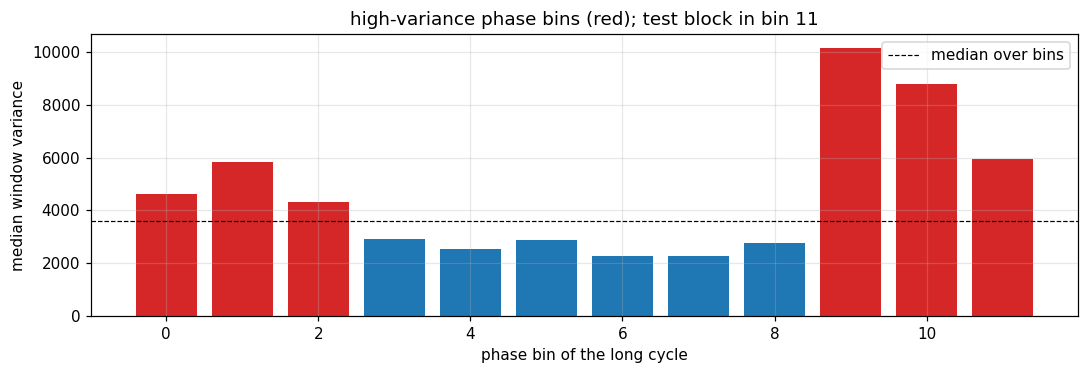

saved final/figures/fig01_highvar_flag.pdf


In [4]:
phase = lambda t0: ((np.asarray(t0) % P_LONG) / P_LONG)
BIN12 = lambda t0: (phase(t0) * 12).astype(int)
REGION = lambda t0: (phase(t0) * 4).astype(int)
L = 168
wins = pd.DataFrame([{"start": s, "bin": int(BIN12(s + L // 2)), "region": int(REGION(s + L // 2)),
                      "cycle": s // P_LONG, "mean": y[s:s + L].mean(), "variance": y[s:s + L].var(),
                      "r(1)": acf(y[s:s + L], nlags=1, fft=True)[1]} for s in range(0, V0 - L + 1, L)])

def kw(v, g):
    groups = [v[g == k] for k in np.unique(g) if (g == k).sum() >= 2]
    if len(groups) < 2 or np.ptp(v) == 0:
        return np.nan, np.nan
    Hs, p = stats.kruskal(*groups); return Hs / (len(v) - 1), p

rows = []
for stat in ["mean", "variance", "r(1)"]:
    e2, p = kw(wins[stat].to_numpy(), wins.region.to_numpy())
    rows.append({"statistic": stat, "scope": "between regions", "ε²": e2, "p": p})
    for q in range(4):
        w = wins[wins.region == q]
        e2b, pb_ = kw(w[stat].to_numpy(), w.bin.to_numpy()); e2c, pc = kw(w[stat].to_numpy(), w.cycle.to_numpy())
        rows.append({"statistic": stat, "scope": f"within region {q}: across bins", "ε²": e2b, "p": pb_})
        rows.append({"statistic": stat, "scope": f"within region {q}: across cycles", "ε²": e2c, "p": pc})
STAT_REGION = pd.DataFrame(rows)
print(STAT_REGION.round(3).to_string(index=False))
STAT_REGION.to_csv(os.path.join(RES, "stationarity_by_region.csv"), index=False)

bin_var = wins.groupby("bin")["variance"].median()
HIGHVAR_BINS = sorted(bin_var[bin_var > bin_var.median()].index.tolist())
TEST_BIN, TEST_REGION = int(BIN12(N + H // 2)), int(REGION(N + H // 2))
print(f"high-variance bins: {HIGHVAR_BINS}; test block: bin {TEST_BIN}, region {TEST_REGION}")
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(bin_var.index, bin_var.values, color=["C3" if b in HIGHVAR_BINS else "C0" for b in bin_var.index])
ax.axhline(bin_var.median(), color="k", ls="--", lw=0.8, label="median over bins")
ax.set_xlabel("phase bin of the long cycle"); ax.set_ylabel("median window variance"); ax.legend()
ax.set_title(f"high-variance phase bins (red); test block in bin {TEST_BIN}")
savefig("highvar_flag")
FLAG_HIGHVAR = np.isin(BIN12(np.arange(NT)), HIGHVAR_BINS).astype(np.float32)

1.000  A <= B at every step
1.000  D decreases only when the active category changes
   share  mean D increment  mean target
G  0.114             2.208       89.880
H  0.323             4.292       70.218
I  0.349             2.594      110.235
J  0.214             0.882      124.963
category -> angle: {'H': 315.0, 'G': 45.0, 'I': 135.0, 'J': None}


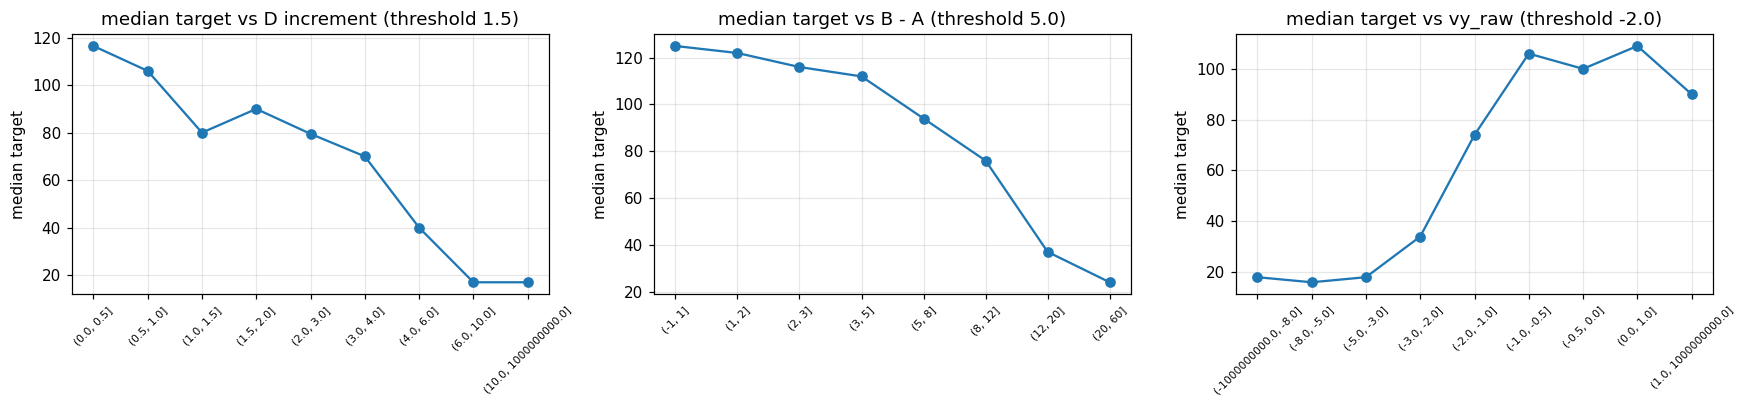

saved final/figures/fig02_threshold_patterns.pdf


In [5]:
def reset_increment(x):
    inc = np.empty_like(x); inc[0] = x[0]; d = np.diff(x); inc[1:] = np.where(d >= 0, d, x[1:]); return inc

def ema(x, tau):
    a = 1.0 / tau; out = np.empty_like(x, dtype=float); acc = x[0]
    for i, v in enumerate(x):
        acc = a * v + (1 - a) * acc; out[i] = acc
    return out

checks = {"A <= B at every step": np.mean(X["A"] <= X["B"] + 1e-9),
          "D decreases only when the active category changes":
              np.mean(np.diff(np.stack([X[k] for k in BIN], 1).argmax(1))[np.diff(X["D"]) < 0] != 0)}
for k, v in checks.items():
    print(f"{v:.3f}  {k}")
d_inc_raw = reset_increment(X["D"])
cat = np.stack([X[k] for k in BIN], 1).argmax(1)
cat_stats = pd.DataFrame({"share": [np.mean(cat == i) for i in range(4)],
                          "mean D increment": [d_inc_raw[cat == i].mean() for i in range(4)],
                          "mean target": [y[cat[:N] == i].mean() for i in range(4)]}, index=BIN)
print(cat_stats.round(3))
ZERO_CAT = cat_stats["mean D increment"].idxmin()
others = cat_stats.drop(ZERO_CAT).sort_values("mean target").index.tolist()
ANGLE = dict(zip(others, [315.0, 45.0, 135.0])); ANGLE[ZERO_CAT] = None
print("category -> angle:", ANGLE)
theta = np.zeros(NT); has_dir = np.ones(NT, bool)
for k, a in ANGLE.items():
    m = X[k] == 1
    if a is None:
        has_dir[m] = False
    else:
        theta[m] = a
mag = np.where(has_dir, d_inc_raw, 0.0)
vx_raw, vy_raw = -mag * np.sin(np.deg2rad(theta)), -mag * np.cos(np.deg2rad(theta))
gap_raw = X["B"] - X["A"]
A_M, B_M = 17.625, 243.04
sat_raw = np.clip(100 * np.exp(A_M * X["A"] / (B_M + X["A"])) / np.exp(A_M * X["B"] / (B_M + X["B"])), 0, 100)
slog = lambda v: np.sign(v) * np.log1p(np.abs(v))

TH_LOW_DINC, TH_LOW_GAP, TH_VY = 1.5, 5.0, -2.0
low_dinc = (d_inc_raw < TH_LOW_DINC).astype(float)
low_both = ((d_inc_raw < TH_LOW_DINC) & (gap_raw < TH_LOW_GAP)).astype(float)
clk = np.empty(NT); c = 240.0
for i in range(NT):
    c = 0.0 if vy_raw[i] <= TH_VY else min(c + 1.0, 240.0); clk[i] = c

counter_rows, BASE_IN, BASE_FEAT = [], [], {}
for k in CONT:
    x = X[k]; dd = np.diff(x[:V0]); drops = dd < 0
    is_counter = bool(x.min() >= 0 and drops.mean() < 0.2 and drops.sum() > 0
                      and np.mean(x[:V0][1:][drops] <= np.quantile(x[:V0], 0.25) + 1e-9) > 0.8)
    sk = stats.skew(x[:V0]); use_log = bool(x.min() >= 0 and sk > 2)
    lvl_name = f"{k}_lvl" if use_log else k
    BASE_FEAT[lvl_name] = np.log1p(x) if use_log else x
    if is_counter:
        inc = reset_increment(x); inc_log = bool(stats.skew(inc[:V0]) > 2)
        BASE_FEAT[f"{k}_inc"] = np.log1p(inc) if inc_log else inc; chg_name = f"{k}_inc"
    else:
        BASE_FEAT[f"{k}_d1"] = np.concatenate([[0.0], np.diff(x)]); chg_name = f"{k}_d1"
    counter_rows.append({"column": k, "share of decreasing steps": drops.mean(), "counter": is_counter,
                         "skewness": sk, "level input": lvl_name, "change input": chg_name})
    BASE_IN += [lvl_name, chg_name]
for k in BIN:
    BASE_FEAT[k] = X[k]; BASE_IN.append(k)
BASE_IN = sorted(BASE_IN, key=lambda c: (c.lower(), c))
COUNTER_TAB = pd.DataFrame(counter_rows).set_index("column")

FEAT = pd.DataFrame({
    **BASE_FEAT,
    "clock_vy": np.log1p(clk),
    "ema12_neg_vy": np.log1p(ema(np.maximum(-vy_raw, 0.0), 12)),
    "ema24_low_Dinc": ema(low_dinc, 24),
    "ema24_low_Dinc_low_gap": ema(low_both, 24),
    "gap_BA": gap_raw,
    "gap_BA_dev24": gap_raw - ema(gap_raw, 24),
    "sat_AB": sat_raw,
    "sat_AB_mean24": pd.Series(sat_raw).rolling(24, min_periods=1).mean().to_numpy(),
    "vec_x": slog(vx_raw), "vec_y": slog(vy_raw),
})
FEAT = FEAT[sorted(FEAT.columns, key=lambda c: (c.lower(), c))]
BINARY_FEATS = list(BIN)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (q, xs, th, nm) in zip(axes, [(d_inc_raw, np.array([0, .5, 1, 1.5, 2, 3, 4, 6, 10, 1e9]), TH_LOW_DINC, "D increment"),
                                     (gap_raw, np.array([-1, 1, 2, 3, 5, 8, 12, 20, 60]), TH_LOW_GAP, "B - A"),
                                     (vy_raw, np.array([-1e9, -8, -5, -3, -2, -1, -0.5, 0, 1, 1e9]), TH_VY, "vy_raw")]):
    bins = pd.cut(q[:V0], xs)
    med = pd.Series(y[:V0]).groupby(bins).median()
    ax.plot(range(len(med)), med.values, marker="o"); ax.set_xticks(range(len(med)))
    ax.set_xticklabels([str(i) for i in med.index], rotation=45, fontsize=7)
    ax.set_title(f"median target vs {nm} (threshold {th})"); ax.set_ylabel("median target")
savefig("threshold_patterns")

In [6]:
FS = {"FS5": sorted(["A", "B", "C", "D_inc", "clock_vy", "ema12_neg_vy", "ema24_low_Dinc", "ema24_low_Dinc_low_gap",
                     "gap_BA", "gap_BA_dev24", "sat_AB", "sat_AB_mean24", "vec_x", "vec_y"], key=lambda c: (c.lower(), c)),
      "FS0": sorted(["A", "B", "D_inc", "D_lvl", "F_inc", "F_lvl", "G", "H", "I", "J"], key=lambda c: (c.lower(), c)),
      "FS1": sorted(["A", "B", "C", "D_inc", "D_lvl", "G", "H", "I", "J", "gap_BA", "sat_AB", "vec_x", "vec_y"], key=lambda c: (c.lower(), c))}
for k_, cs_ in FS.items():
    assert all(c in FEAT.columns for c in cs_), k_

In [7]:
tt_all = np.arange(NT)
PHASE_ONLY = np.stack([np.sin(2 * np.pi * tt_all / P_SHORT), np.cos(2 * np.pi * tt_all / P_SHORT),
                       np.sin(2 * np.pi * tt_all / P_LONG), np.cos(2 * np.pi * tt_all / P_LONG)], 1).astype(np.float32)
POSF = np.concatenate([np.stack([(tt_all % P_SHORT) / (P_SHORT - 1) - 0.5,
                                 ((tt_all // P_SHORT) % 7) / 6.0 - 0.5,
                                 (tt_all % P_LONG) / (P_LONG - 1) - 0.5,
                                 np.floor(12 * (tt_all % P_LONG) / P_LONG) / 11.0 - 0.5], 1), PHASE_ONLY], 1).astype(np.float32)
d2 = np.abs(np.diff(y, 2)); smooth = np.concatenate([[False], d2 <= 1, [False]])
edges = np.diff(np.concatenate([[0], smooth.astype(int), [0]]))
starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0]
INTERP = np.zeros(NT, bool)
for s0, e0 in zip(starts, ends):
    if e0 - s0 >= 6:
        INTERP[max(0, s0 - 1):min(N, e0 + 1)] = True
print(f"interpolated points: {int(INTERP.sum())} ({INTERP[:N].mean():.2%})")

def trajectory_features(Z):
    out = [np.concatenate([np.zeros(k), Z[k:] - Z[:-k]]) for k in (1, 3, 6)]
    out.append(INTERP.astype(np.float32))
    F_ = np.stack(out, 1).astype(np.float32); F_[N:] = 0.0
    return F_

N_PROFILE_BINS = 48
def phase_profile(fit_end):
    b = (phase(np.arange(NT)) * N_PROFILE_BINS).astype(int)
    lyf = ly[:fit_end]; bf = b[:fit_end]; ok = ~INTERP[:fit_end]
    stats_ = np.array([[lyf[(bf == k) & ok].mean(), lyf[(bf == k) & ok].std(), np.quantile(lyf[(bf == k) & ok], 0.9)]
                       for k in range(N_PROFILE_BINS)])
    kern = np.array([1, 1, 1]) / 3.0
    sm = np.stack([np.convolve(np.r_[stats_[-1:, j], stats_[:, j], stats_[:1, j]], kern, mode="valid")
                   for j in range(3)], 1)
    return sm[b]

def build_covariates(fit_end, fs, flag=None, interact=False, profile=False):
    cols = FS[fs] if isinstance(fs, str) else list(fs)
    df = FEAT[cols].copy()
    cont = [c for c in cols if c not in BINARY_FEATS]
    mu, sd = df[cont].iloc[:fit_end].mean(), df[cont].iloc[:fit_end].std() + 1e-8
    df[cont] = (df[cont] - mu) / sd
    if profile:
        pr = phase_profile(fit_end)
        for j, nm in enumerate(["profile_mean", "profile_sd", "profile_q90"]):
            v = pr[:, j]; df[nm] = (v - v[:fit_end].mean()) / (v[:fit_end].std() + 1e-8)
    if flag == "highvar":
        if interact:
            for c in cols:
                df[f"{c}×flag"] = df[c].to_numpy() * FLAG_HIGHVAR
        df["flag_highvar"] = FLAG_HIGHVAR
    return df.to_numpy(np.float32), list(df.columns)

interpolated points: 2029 (4.65%)


In [8]:
VAL_REGION = REGION(VAL_ORIGINS + H // 2)
SEGS = {"h1-24": slice(0, 24), "h25-72": slice(24, 72), "h73-168": slice(72, 168)}

def block_metrics(yt, yp):
    e = yp - yt; den = np.abs(yt) + np.abs(yp)
    sm = np.where(den == 0, 0.0, 2 * np.abs(e) / np.where(den == 0, 1, den))
    sy, sp = yt.std(), yp.std()
    rr = np.corrcoef(yt, yp)[0, 1] if sy > 0 and sp > 0 else 0.0
    return {"MAE": np.mean(np.abs(e)), "sMAPE": 100 * np.mean(sm), "RMSE": np.sqrt(np.mean(e ** 2)),
            "Murphy bias2": (yp.mean() - yt.mean()) ** 2, "Murphy scale": (sy - sp) ** 2,
            "Murphy timing": 2 * sy * sp * (1 - rr), "sd ratio": sp / (sy + 1e-9)}

def evaluate(FC, origins=VAL_ORIGINS):
    rows = []
    for o, fc in zip(origins, FC):
        fc = np.asarray(fc); yt_ = y[o:o + H]; keep = ~INTERP[o:o + H]
        r_ = {"origin": int(o), "region": int(REGION(o + H // 2)), **block_metrics(yt_[keep], fc[keep])}
        for nm, sl in SEGS.items():
            k = keep[sl]
            r_[f"RMSE {nm}"] = np.sqrt(np.mean((fc[sl][k] - yt_[sl][k]) ** 2)) if k.any() else np.nan
        rows.append(r_)
    return pd.DataFrame(rows)

METRIC_COLS = ["RMSE", "MAE", "sMAPE", "Murphy bias2", "Murphy scale", "Murphy timing",
               "RMSE h1-24", "RMSE h25-72", "RMSE h73-168", "sd ratio"]

In [9]:
from sklearn.linear_model import Ridge
TAUS = np.array([2.0, 8.0, 24.0, 72.0])
def ridge_design(origins, C, marks):
    O = np.asarray(origins); h = np.arange(H); n = len(O)
    idx = O[:, None] + h[None, :]
    cs = np.concatenate([[0.0], np.cumsum(y)])
    hist = np.stack([y[O - 1], (cs[O] - cs[O - 24]) / 24, (cs[O] - cs[O - 168]) / 168], 1)
    Bm = np.exp(-h[:, None] / TAUS[None, :])
    inter = (hist[:, None, :, None] * Bm[None, :, None, :]).reshape(n, H, -1)
    Xd = np.concatenate([np.repeat(hist[:, None, :], H, 1), inter, np.repeat(Bm[None], n, 0), marks[idx], C[idx]], -1)
    return Xd.reshape(n * H, -1), y[np.minimum(idx, N - 1)].reshape(-1), (~INTERP[np.minimum(idx, NT - 1)]).reshape(-1)

def ridge_forecast(fs):
    C, _ = build_covariates(V0, fs)
    Xtr, ttr, wtr = ridge_design(np.arange(720, V0 - H + 1, 12), C, PHASE_ONLY)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-8
    m = Ridge(alpha=10.0).fit((Xtr - mu) / sd, ttr, sample_weight=wtr.astype(float))
    Xv, _, _ = ridge_design(VAL_ORIGINS, C, PHASE_ONLY)
    return np.clip(m.predict((Xv - mu) / sd).reshape(len(VAL_ORIGINS), H), 0, None)

REFERENCE = {"climatology": evaluate(np.full((N_VAL, H), y[:V0].mean())),
             "ridge FS0": evaluate(ridge_forecast("FS0")),
             "ridge FS1": evaluate(ridge_forecast("FS1")),
             "ridge FS5": evaluate(ridge_forecast("FS5"))}
print(pd.DataFrame({k: v[METRIC_COLS].mean() for k, v in REFERENCE.items()}).T.round(2))

              RMSE    MAE  sMAPE  Murphy bias2  Murphy scale  Murphy timing  RMSE h1-24  RMSE h25-72  RMSE h73-168  sd ratio
climatology  82.82  68.49  75.68       2443.54       6124.35           0.00       85.53        75.01         79.01      0.00
ridge FS0    59.51  47.18  64.62       1179.94       1257.90        1750.98       47.08        58.72         58.71      0.73
ridge FS1    59.17  46.32  61.69       1255.69       1249.58        1714.94       46.33        58.14         58.39      0.74
ridge FS5    57.42  45.43  60.38       1208.03       1003.77        1738.10       48.79        56.65         55.78      0.82


In [10]:
MA_STRIDE = 1
EMB_K = 3
class MovingAvg(nn.Module):
    def __init__(self, kernel):
        super().__init__()
        assert kernel % 2 == 1, "use an odd kernel"
        self.k, self.s = kernel, MA_STRIDE
        self.pool = nn.AvgPool1d(kernel, stride=self.s)
    def forward(self, x):
        L = x.shape[1]; pad = (self.k - 1) // 2
        x = torch.cat([x[:, :1].repeat(1, pad, 1), x, x[:, -1:].repeat(1, pad, 1)], 1)
        out = self.pool(x.transpose(1, 2))
        if self.s > 1:
            out = nn.functional.interpolate(out, size=L, mode="linear", align_corners=True)
        return out.transpose(1, 2)

class SeriesDecomp(nn.Module):
    def __init__(self, kernel):
        super().__init__()
        self.ma = MovingAvg(kernel)
    def forward(self, x):
        trend = self.ma(x)
        return x - trend, trend

class SeasonalLayerNorm(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.ln = nn.LayerNorm(d)
    def forward(self, x):
        x = self.ln(x)
        return x - x.mean(1, keepdim=True)

class AutoCorrelation(nn.Module):
    def __init__(self, factor=1, top_k=None):
        super().__init__()
        self.factor, self.fixed_k = factor, top_k
        self.last_delays = None
    def forward(self, q, k, v):
        B, L, Hh, E = q.shape
        S = k.shape[1]
        if L > S:
            z = torch.zeros_like(q[:, : L - S])
            k, v = torch.cat([k, z], 1), torch.cat([v, z], 1)
        else:
            k, v = k[:, :L], v[:, :L]
        qf = torch.fft.rfft(q.permute(0, 2, 3, 1).contiguous(), dim=-1)
        kf = torch.fft.rfft(k.permute(0, 2, 3, 1).contiguous(), dim=-1)
        corr = torch.fft.irfft(qf * torch.conj(kf), n=L, dim=-1)
        vals = v.permute(0, 2, 3, 1).contiguous()
        top_k = min(L, self.fixed_k) if self.fixed_k else max(1, int(self.factor * math.log(L)))
        mean_corr = corr.mean(1).mean(1)
        weights, delay = torch.topk(mean_corr, top_k, dim=-1)
        w = torch.softmax(weights, -1)
        self.last_delays = delay.detach()
        idx0 = torch.arange(L, device=q.device).view(1, 1, 1, L)
        vals2 = vals.repeat(1, 1, 1, 2)
        agg = torch.zeros_like(vals)
        for i in range(top_k):
            idx = (idx0 + delay[:, i].view(B, 1, 1, 1)).expand(B, Hh, E, L)
            agg = agg + torch.gather(vals2, -1, idx) * w[:, i].view(B, 1, 1, 1)
        return agg.permute(0, 3, 1, 2)

class AutoCorrelationLayer(nn.Module):
    def __init__(self, d_model, n_heads, factor, top_k=None):
        super().__init__()
        self.inner = AutoCorrelation(factor, top_k)
        self.q, self.k, self.v = (nn.Linear(d_model, d_model) for _ in range(3))
        self.o = nn.Linear(d_model, d_model)
        self.h = n_heads
    def forward(self, q, k, v):
        B, L, _ = q.shape
        S = k.shape[1]
        out = self.inner(self.q(q).view(B, L, self.h, -1), self.k(k).view(B, S, self.h, -1),
                         self.v(v).view(B, S, self.h, -1))
        return self.o(out.reshape(B, L, -1))

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff, bias=False), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(d_ff, d_model, bias=False), nn.Dropout(dropout))
    def forward(self, x): return self.net(x)

class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, kernel, factor, dropout, top_k=None):
        super().__init__()
        self.attn = AutoCorrelationLayer(d_model, n_heads, factor, top_k)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.dec1, self.dec2 = SeriesDecomp(kernel), SeriesDecomp(kernel)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        x, _ = self.dec1(x + self.drop(self.attn(x, x, x)))
        x, _ = self.dec2(x + self.ff(x))
        return x

class DecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, kernel, factor, dropout, c_out=1, top_k=None):
        super().__init__()
        self.self_attn = AutoCorrelationLayer(d_model, n_heads, factor, top_k)
        self.cross_attn = AutoCorrelationLayer(d_model, n_heads, factor, top_k)
        self.ff = FeedForward(d_model, d_ff, dropout)
        self.dec1, self.dec2, self.dec3 = SeriesDecomp(kernel), SeriesDecomp(kernel), SeriesDecomp(kernel)
        self.drop = nn.Dropout(dropout)
        self.trend_proj = nn.Conv1d(d_model, c_out, 3, padding=1, padding_mode="circular", bias=False)
    def forward(self, x, cross):
        x, t1 = self.dec1(x + self.drop(self.self_attn(x, x, x)))
        x, t2 = self.dec2(x + self.drop(self.cross_attn(x, cross, cross)))
        x, t3 = self.dec3(x + self.ff(x))
        trend = self.trend_proj((t1 + t2 + t3).transpose(1, 2)).transpose(1, 2)
        return x, trend

class Embedding(nn.Module):
    def __init__(self, c_in, n_mark, d_model, dropout):
        super().__init__()
        self.val = nn.Conv1d(c_in, d_model, EMB_K, padding=EMB_K // 2, padding_mode="circular", bias=False)
        self.mark = nn.Linear(n_mark, d_model, bias=False)
        self.drop = nn.Dropout(dropout)
    def forward(self, x, m):
        return self.drop(self.val(x.transpose(1, 2)).transpose(1, 2) + self.mark(m))

class CovTrendHead(nn.Module):
    def __init__(self, n_cov, n_mark, hidden=16, taus=(2.0, 8.0, 24.0, 72.0)):
        super().__init__()
        n_in = n_cov + n_mark
        self.g = nn.Linear(n_in, 1) if hidden == 0 else nn.Sequential(
            nn.Linear(n_in, hidden), nn.GELU(), nn.Linear(hidden, 1))
        self.register_buffer("decay", torch.exp(-torch.arange(H).float()[:, None] / torch.tensor(taus)[None, :]))
        self.a = nn.Parameter(torch.zeros(len(taus)))
    def forward(self, cov_fut, mark_fut, cov_last, mark_last, y_last):
        lvl = self.g(torch.cat([cov_fut, mark_fut], -1))
        lvl_last = self.g(torch.cat([cov_last, mark_last], -1))
        w = (self.decay @ torch.sigmoid(self.a)).view(1, H, 1) / len(self.a)
        return lvl + w * (y_last - lvl_last)

class Autoformer(nn.Module):
    def __init__(self, enc_in, dec_in, n_mark, cfg):
        super().__init__()
        d, self.L, self.lab = cfg["d_model"], cfg["seq_len"], cfg["label_len"]
        self.decomp = SeriesDecomp(cfg["moving_avg"])
        self.enc_emb = Embedding(enc_in, n_mark, d, cfg["dropout"])
        self.dec_emb = Embedding(dec_in, n_mark, d, cfg["dropout"])
        self.enc_layers = nn.ModuleList([EncoderLayer(d, cfg["n_heads"], cfg["d_ff"], cfg["moving_avg"],
                                                      cfg["factor"], cfg["dropout"], top_k=cfg.get("top_k"))
                                         for _ in range(cfg["e_layers"])])
        self.enc_norm = SeasonalLayerNorm(d)
        self.dec_layers = nn.ModuleList([DecoderLayer(d, cfg["n_heads"], cfg["d_ff"], cfg["moving_avg"],
                                                      cfg["factor"], cfg["dropout"], top_k=cfg.get("top_k"))
                                         for _ in range(cfg["d_layers"])])
        self.dec_norm = SeasonalLayerNorm(d)
        self.out = nn.Linear(d, 1)
        self.revin = cfg["norm"] == "revin"
        self.trend_init = cfg.get("trend_init", "window")
        self.head_only = cfg.get("head_only", False)
        if self.trend_init == "cov":
            assert dec_in > 1, "trend_init='cov' needs covariates in the decoder (cov_mode 'dec' or 'both')"
            self.head = CovTrendHead(dec_in - 1, n_mark, cfg.get("head_hidden", 16))

    def forward(self, x_enc, m_enc, dec_cov, m_dec):
        tgt = x_enc[..., :1]
        if self.revin:
            mu = tgt.mean(1, keepdim=True).detach()
            sd = tgt.std(1, keepdim=True).detach() + 1e-5
            tgt = (tgt - mu) / sd
            x_enc = torch.cat([tgt, x_enc[..., 1:]], -1)
        B = x_enc.shape[0]
        seasonal, trend = self.decomp(tgt)
        if self.trend_init == "cov":
            lab = self.lab
            fut = self.head(dec_cov[:, lab:], m_dec[:, lab:], dec_cov[:, lab - 1:lab], m_dec[:, lab - 1:lab], tgt[:, -1:])
        else:
            fut = tgt.mean(1, keepdim=True).repeat(1, H, 1)
        if self.head_only:
            out = fut[:, :, 0]
            return out * sd[:, :, 0] + mu[:, :, 0] if self.revin else out
        trend = torch.cat([trend[:, -self.lab:], fut], 1)
        seasonal = torch.cat([seasonal[:, -self.lab:], torch.zeros(B, H, 1, device=x_enc.device)], 1)
        enc = self.enc_emb(x_enc, m_enc)
        for layer in self.enc_layers:
            enc = layer(enc)
        enc = self.enc_norm(enc)
        dec = self.dec_emb(torch.cat([seasonal, dec_cov], -1), m_dec)
        for layer in self.dec_layers:
            dec, t = layer(dec, enc)
            trend = trend + t
        out = (trend + self.out(self.dec_norm(dec)))[:, -H:, 0]
        if self.revin:
            out = out * sd[:, :, 0] + mu[:, :, 0]
        return out

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [11]:
BASE_CFG = dict(seq_len=336, label_len=168, d_model=8, n_heads=4, e_layers=1, d_layers=1, d_ff=16,
                moving_avg=25, factor=1, top_k=None, dropout=0.2, cov_mode="both", norm="global",
                trend_init="cov", head_hidden=16, head_only=False,
                fs="FS0", marks="phase", traj=False, mask_interp=False, flag=None, flag_interact=False,
                lr=1e-3, lr_gamma=0.95, body_lr_mult=0.3, head_lr_mult=3.0, batch_size=128,
                max_epochs=40, patience=6, train_stride=4)
SEEDS = [0, 1, 2]
if SMOKE:
    BASE_CFG.update(seq_len=96, label_len=48, max_epochs=1, train_stride=97); SEEDS = [0]

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class Batcher:
    def __init__(self, Z, C, E, M, W, cfg):
        dv = DEVICE
        self.Z, self.C, self.M, self.W, self.E = (torch.tensor(a, device=dv) for a in (Z, C, M, W, E))
        self.enc_cov = cfg["cov_mode"] == "both"
        self.eo = torch.arange(-cfg["seq_len"], 0, device=dv)
        self.do = torch.arange(-cfg["label_len"], H, device=dv)
        self.to = torch.arange(0, H, device=dv)
    def get(self, origins):
        o = torch.as_tensor(origins, device=self.Z.device).long()[:, None]
        ie, idd, it = o + self.eo, o + self.do, o + self.to
        enc = [self.Z[ie][..., None]] + ([self.C[ie]] if self.enc_cov else []) + ([self.E[ie]] if self.E.shape[1] else [])
        return torch.cat(enc, -1), self.M[ie], self.C[idd], self.M[idd], self.Z[it], self.W[it]

def episode_features(cut):
    q20 = np.quantile(y[:cut], 0.2); sd = y[:cut].std()
    since = np.zeros(NT); rise = np.zeros(NT); c_ = 0.0; low = y[0]
    for t in range(N):
        if y[t] <= q20:
            c_, low = 0.0, y[t]
        else:
            c_ += 1.0; low = min(low, y[t])
        since[t] = c_; rise[t] = (y[t] - low) / sd
    return np.stack([np.log1p(since) / np.log1p(240.0), rise], 1).astype(np.float32)

def prepare(cut, cfg):
    mu, sd = y[:cut].mean(), y[:cut].std()
    Z = np.zeros(NT, np.float32); Z[:N] = (y - mu) / sd
    C, _ = build_covariates(cut, cfg["fs"], cfg["flag"], cfg["flag_interact"], cfg.get("profile", False))
    E = trajectory_features(Z) if cfg["traj"] else np.zeros((NT, 0), np.float32)
    if cfg.get("episode"):
        E = np.concatenate([E, episode_features(cut)], 1)
    if cfg.get("p_long") or cfg.get("long_harmonics", 1) > 1:
        tt_ = np.arange(NT); pl = cfg.get("p_long") or P_LONG
        cols_ = [np.sin(2 * np.pi * tt_ / P_SHORT), np.cos(2 * np.pi * tt_ / P_SHORT)]
        for hk in range(1, cfg.get("long_harmonics", 1) + 1):
            cols_ += [np.sin(2 * np.pi * hk * tt_ / pl), np.cos(2 * np.pi * hk * tt_ / pl)]
        M = np.stack(cols_, 1).astype(np.float32)
    else:
        M = POSF if cfg["marks"] == "pos" else PHASE_ONLY
    W = (~INTERP).astype(np.float32) if cfg["mask_interp"] else np.ones(NT, np.float32)
    return Batcher(Z, C, E, M, W, cfg), (lambda z: np.clip(z * sd + mu, 0, None))

def build_model(cfg, b):
    global MA_STRIDE, EMB_K
    MA_STRIDE, EMB_K = cfg.get("ma_stride", 1), cfg.get("emb_kernel", 3)
    n_cov = b.C.shape[1]
    enc_in = 1 + (n_cov if cfg["cov_mode"] == "both" else 0) + b.E.shape[1]
    return Autoformer(enc_in, 1 + n_cov, b.M.shape[1], cfg).to(DEVICE)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def predict(model, b, to_raw, origins, bs=256):
    model.eval(); out = []
    for i in range(0, len(origins), bs):
        xe, me, dc, md, _, _ = b.get(origins[i:i + bs])
        out.append(model(xe, me, dc, md).cpu().numpy())
    return to_raw(np.concatenate(out))

def train_model(cfg, seed, cut, es_origins, verbose=True):
    set_seed(seed)
    b, to_raw = prepare(cut, cfg)
    model = build_model(cfg, b)
    head_p = [p for n, p in model.named_parameters() if n.startswith("head.")]
    body_p = [p for n, p in model.named_parameters() if not n.startswith("head.")]
    groups = [{"params": body_p, "lr": cfg["lr"] * cfg["body_lr_mult"]}]
    if head_p:
        groups.append({"params": head_p, "lr": cfg["lr"] * cfg["head_lr_mult"]})
    opt = torch.optim.Adam(groups)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=cfg["lr_gamma"])
    tr = np.arange(cfg["seq_len"], cut - H + 1, cfg["train_stride"])
    g = torch.Generator().manual_seed(seed)
    best, best_state, best_ep, wait, ep = np.inf, None, 0, 0, 0
    for ep in range(1, cfg["max_epochs"] + 1):
        model.train(); losses = []
        perm = tr[torch.randperm(len(tr), generator=g).numpy()]
        for i in range(0, len(perm), cfg["batch_size"]):
            xe, me, dc, md, tgt, w = b.get(perm[i:i + cfg["batch_size"]])
            loss = ((model(xe, me, dc, md) - tgt) ** 2 * w).sum() / w.sum().clamp_min(1.0)
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        sched.step()
        es = evaluate(predict(model, b, to_raw, es_origins), es_origins).RMSE.mean()
        if verbose:
            print(f"    epoch {ep:2d}  train_mse {np.mean(losses):.3f}  es_rmse {es:.2f}", flush=True)
        if es < best - 1e-6:
            best, best_state, best_ep, wait = es, copy.deepcopy(model.state_dict()), ep, 0
        else:
            wait += 1
        if wait >= cfg["patience"]:
            break
    model.load_state_dict(best_state)
    return model, b, to_raw, {"P": count_params(model), "epochs_run": ep, "best_epoch": best_ep}

def cfg_key(cfg, seed):
    return hashlib.md5(json.dumps({**cfg, "seed": seed, "smoke": SMOKE, "P_long": P_LONG}, sort_keys=True,
                                  default=str).encode()).hexdigest()[:12]

def run_experiment(cfg, seed, verbose=False):
    key = cfg_key(cfg, seed)
    fb, fm, ff = (os.path.join(RES, f"{key}_{s}") for s in ("blocks.csv", "meta.json", "fc.npy"))
    if os.path.exists(fm):
        return pd.read_csv(fb), json.load(open(fm)), np.load(ff)
    model, b, to_raw, info = train_model(cfg, seed, TRAIN_END, ES_ORIGINS, verbose=verbose)
    fc = predict(model, b, to_raw, VAL_ORIGINS)
    bdf = evaluate(fc)
    meta = {"cfg": cfg, "seed": seed, **info}
    bdf.to_csv(fb, index=False); json.dump(meta, open(fm, "w"), default=str); np.save(ff, fc)
    return bdf, meta, fc

_b, _to_raw = prepare(TRAIN_END, {**BASE_CFG, "fs": "FS5", "traj": True})
_xe, *_ = _b.get(np.array([VAL_ORIGINS[0]]))
_mu, _sd = y[:TRAIN_END].mean(), y[:TRAIN_END].std()
assert np.allclose(_xe[0, :, 0].cpu().numpy(), (y[VAL_ORIGINS[0] - BASE_CFG["seq_len"]:VAL_ORIGINS[0]] - _mu) / _sd, atol=1e-5)

In [12]:
F5_RECIPE = dict(angles=(("G", 45.0), ("H", 315.0), ("I", 135.0), ("J", None)), th_D=1.5, th_gap=5.0, th_vy=-2.0, cap=240.0,
                 w_negvy=12, w_low=24, w_joint=24, w_gapdev=24, w_satmean=24, sat=("fixed",), op="B−A",
                 relations=(), events=())
_cache = {}
def _vec(angles):
    key = ("vec", angles)
    if key not in _cache:
        ang = dict(angles); thv = np.zeros(NT); hv = np.ones(NT, bool)
        for k_, a_ in ang.items():
            m_ = X[k_] == 1
            if a_ is None: hv[m_] = False
            else: thv[m_] = a_
        mg = np.where(hv, d_inc_raw, 0.0)
        _cache[key] = (-mg * np.sin(np.deg2rad(thv)), -mg * np.cos(np.deg2rad(thv)))
    return _cache[key]
def _clock(ind, cap):
    out = np.empty(NT); c_ = cap
    for i_, b_ in enumerate(ind):
        c_ = 0.0 if b_ else min(c_ + 1.0, cap); out[i_] = c_
    return out
def _put(name, fn):
    if name not in FEAT.columns:
        FEAT[name] = fn()
    return name
_RES_FIT = TRAIN_END
def _resid(a_, b_):
    coef = np.polyfit(X[b_][:_RES_FIT], X[a_][:_RES_FIT], 1); return X[a_] - np.polyval(coef, X[b_])

REL_EXTRA = {}
def recipe_inputs(r):
    a_key = "/".join(f"{k}{'' if v is None else int(v) if float(v).is_integer() else v}" for k, v in r["angles"])
    vx, vy = _vec(r["angles"])
    cols = ["A", "B", "C", "D_inc"]
    cols.append(_put(f"vec_x[{a_key}]", lambda: slog(vx))); cols.append(_put(f"vec_y[{a_key}]", lambda: slog(vy)))
    cols.append(_put(f"clock_vy[{a_key}|{r['th_vy']}|{r['cap']}]", lambda: np.log1p(_clock(vy <= r["th_vy"], r["cap"]))))
    cols.append(_put(f"ema_negvy[{a_key}|{r['w_negvy']}]", lambda: np.log1p(ema(np.maximum(-vy, 0.0), r["w_negvy"]))))
    cols.append(_put(f"ema_lowD[{r['th_D']}|{r['w_low']}]", lambda: ema((d_inc_raw < r["th_D"]).astype(float), r["w_low"])))
    cols.append(_put(f"ema_lowD_lowgap[{r['th_D']}|{r['th_gap']}|{r['w_joint']}]",
                     lambda: ema(((d_inc_raw < r["th_D"]) & (gap_raw < r["th_gap"])).astype(float), r["w_joint"])))
    ops = {"B−A": lambda: X["B"] - X["A"], "A+B": lambda: X["A"] + X["B"], "A·B": lambda: X["A"] * X["B"],
           "A/B": lambda: X["A"] / np.where(np.abs(X["B"]) < 0.5, np.sign(X["B"] + 1e-9) * 0.5, X["B"]),
           "B/A": lambda: X["B"] / np.where(np.abs(X["A"]) < 0.5, np.sign(X["A"] + 1e-9) * 0.5, X["A"])}
    if r["op"] != "none":
        cols.append(_put(f"op[{r['op']}]", ops[r["op"]]))
        cols.append(_put(f"op_dev[{r['op']}|{r['w_gapdev']}]", lambda: (lambda v: v - ema(v, r["w_gapdev"]))(ops[r["op"]]())))
    s_ = r["sat"]
    if s_[0] != "none":
        if s_[0] == "fixed":
            base_name, base_fn = "sat[fixed]", lambda: sat_raw
        elif s_[0] == "ratio":
            base_name = f"sat[ratio|{s_[1]}|{s_[2]}]"
            base_fn = lambda: np.clip(100 * np.exp(s_[1] * X["A"] / (s_[2] + X["A"]) - s_[1] * X["B"] / (s_[2] + X["B"])), 0, 100)
        else:
            base_name, base_fn = f"sat[expgap|{s_[1]}]", lambda: 100 * np.exp(-s_[1] * gap_raw)
        cols.append(_put(base_name, base_fn))
        cols.append(_put(f"{base_name}_mean[{r['w_satmean']}]",
                         lambda: pd.Series(FEAT[base_name].to_numpy()).rolling(int(r["w_satmean"]), min_periods=1).mean().to_numpy()))
    rel = {"C net of B": lambda: _resid("C", "B"), "A net of C": lambda: _resid("A", "C"),
           "D increase × C": lambda: np.log1p(d_inc_raw) * (X["C"] - X["C"][:_RES_FIT].mean()) / X["C"][:_RES_FIT].std(),
           "(A+B)/2": lambda: (X["A"] + X["B"]) / 2,
           "clock E or F active": lambda: np.log1p(_clock((reset_increment(X["E"]) > 0) | (reset_increment(X["F"]) > 0), 240.0))}
    rel.update(REL_EXTRA)
    for nm_ in r["relations"]:
        cols.append(_put(f"rel[{nm_}]", rel[nm_]))
    for col_ in r["events"]:
        act_ = reset_increment(X[col_]) > 0
        cols.append(_put(f"clock_{col_}", lambda: np.log1p(_clock(act_, 240.0))))
        cols.append(_put(f"ema24_{col_}", lambda: ema(act_.astype(float), 24)))
    return sorted(cols, key=lambda c: (c.lower(), c))

_f5_cols = recipe_inputs(F5_RECIPE)
_map = {"vec_x": "vec_x[G45/H315/I135/J]", "vec_y": "vec_y[G45/H315/I135/J]", "clock_vy": "clock_vy[G45/H315/I135/J|-2.0|240.0]",
        "ema12_neg_vy": "ema_negvy[G45/H315/I135/J|12]", "ema24_low_Dinc": "ema_lowD[1.5|24]",
        "ema24_low_Dinc_low_gap": "ema_lowD_lowgap[1.5|5.0|24]", "gap_BA": "op[B−A]", "gap_BA_dev24": "op_dev[B−A|24]",
        "sat_AB": "sat[fixed]", "sat_AB_mean24": "sat[fixed]_mean[24]"}
for orig, new in _map.items():
    assert new in _f5_cols, (orig, new)
    assert np.allclose(FEAT[orig].to_numpy(), FEAT[new].to_numpy(), atol=1e-9), f"recipe does not reproduce {orig}"

In [13]:
F5_OV = {"traj": True, "mask_interp": True}
def cfg_of(r):
    return {**BASE_CFG, **F5_OV, "fs": recipe_inputs(r)}
def with_(**kw):
    r = dict(F5_RECIPE); r.update(kw); return r
FINAL_RECIPE = with_(sat=("expgap", 0.1), events=("E", "F"))
RUN_GRIDS = False
RUN_RELATIONS = False

In [14]:
def per_block(results, key):
    return pd.concat([r_[0] for r_ in results[key]]).groupby("origin", sort=False).mean(numeric_only=True).reset_index()
def summary(results, ref_key):
    ref = per_block(results, ref_key); rows = []
    for key in results:
        pb = per_block(results, key); d = pb.RMSE.to_numpy() - ref.RMSE.to_numpy()
        seed_rmse = [r_[0].RMSE.mean() for r_ in results[key]]
        rows.append({"configuration": key, "P": results[key][0][1]["P"],
                     "epochs": np.mean([r_[1]["epochs_run"] for r_ in results[key]]),
                     "RMSE": pb.RMSE.mean(), "seed sd": np.std(seed_rmse, ddof=1) if len(seed_rmse) > 1 else np.nan,
                     "MAE": pb.MAE.mean(), "sMAPE": pb.sMAPE.mean(),
                     "dRMSE": d.mean(), "wins": np.mean(d < 0),
                     "p": stats.wilcoxon(pb.RMSE, ref.RMSE).pvalue if np.any(d != 0) else 1.0,
                     f"dRMSE region {TEST_REGION}": d[VAL_REGION == TEST_REGION].mean(),
                     "RMSE h1-24": pb["RMSE h1-24"].mean(), "RMSE h73-168": pb["RMSE h73-168"].mean()})
    return pd.DataFrame(rows)

In [15]:
MAIN = {"F5": [run_experiment(cfg_of(F5_RECIPE), s_) for s_ in SEEDS],
        "final": [run_experiment(cfg_of(FINAL_RECIPE), s_) for s_ in SEEDS]}
MAIN_TAB = summary(MAIN, "F5")
print(MAIN_TAB.round(3).to_string(index=False))
FC_ENS = np.mean([r_[2] for r_ in MAIN["final"]], 0)
print("final model, three-seed ensemble validation RMSE:", round(evaluate(FC_ENS).RMSE.mean(), 2))
MAIN_TAB.to_csv(os.path.join(RES, "main_results.csv"), index=False)

configuration    P  epochs   RMSE  seed sd    MAE  sMAPE  dRMSE  wins     p  dRMSE region 3  RMSE h1-24  RMSE h73-168
           F5 2646    26.0 50.032    0.583 38.592 50.577  0.000 0.000 1.000           0.000      42.515        47.911
        final 2902    16.0 47.336    0.121 36.037 48.086 -2.696 0.596 0.026          -4.061      41.234        45.605
final model, three-seed ensemble validation RMSE: 46.8


In [16]:
if RUN_GRIDS:
    GRIDS = {}
    GRIDS["angles"] = {f"G{g} H{h} I{i}": with_(angles=(("G", float(g)), ("H", float(h)), ("I", float(i)), ("J", None)))
                       for g in (30, 60) for h in (300, 330) for i in (120, 150)}
    GRIDS["angles"]["J 225"] = with_(angles=(("G", 45.0), ("H", 315.0), ("I", 135.0), ("J", 225.0)))
    GRIDS["angles"]["G0 H120 I240"] = with_(angles=(("G", 0.0), ("H", 120.0), ("I", 240.0), ("J", None)))
    GRIDS["constants"] = {f"c2={c2} c3={c3}": with_(sat=("ratio", float(c2), float(c3))) for c2 in (10, 15, 20, 25) for c3 in (200, 250, 300)}
    GRIDS["constants"].update({"exp(-0.05 gap)": with_(sat=("expgap", 0.05)), "exp(-0.1 gap)": with_(sat=("expgap", 0.1)),
                               "none": with_(sat=("none",))})
    GRIDS["threshold D increase"] = {f"r < {v}": with_(th_D=float(v)) for v in (1, 2, 3, 4)}
    GRIDS["threshold gap"] = {f"g < {v}": with_(th_gap=float(v)) for v in (3, 6, 9, 12)}
    GRIDS["threshold vy"] = {f"y <= {v}": with_(th_vy=float(v)) for v in (-1, -3, -4)}
    GRIDS["clock cap"] = {f"cap {v}": with_(cap=float(v)) for v in (120, 480)}
    for wk in ["w_negvy", "w_low", "w_joint", "w_gapdev", "w_satmean"]:
        GRIDS[f"window {wk[2:]}"] = {f"{wk[2:]} = {v}": with_(**{wk: v}) for v in (6, 12, 24, 48) if v != F5_RECIPE[wk]}
    GRIDS["operation on (A, B)"] = {op_: with_(op=op_) for op_ in ("A+B", "A·B", "A/B", "B/A", "none")}
    GRIDS["relations"] = {f"+ {nm_}": with_(relations=(nm_,)) for nm_ in
                          ("C net of B", "A net of C", "D increase × C", "(A+B)/2", "clock E or F active")}
    GRIDS["E and F"] = {"+ E": with_(events=("E",)), "+ F": with_(events=("F",)), "+ E and F": with_(events=("E", "F"))}
    GRID_TABS = []
    for gname, grid in GRIDS.items():
        res = {"F5": MAIN["F5"]}
        for lab, r in grid.items():
            res[lab] = [run_experiment(cfg_of(r), s_) for s_ in SEEDS]
        t_ = summary(res, "F5"); t_.insert(0, "grid", gname); GRID_TABS.append(t_)
        print(t_.round(3).to_string(index=False))
    pd.concat(GRID_TABS).to_csv(os.path.join(RES, "grid_results.csv"), index=False)

In [17]:
if RUN_RELATIONS:
    FIT = _RES_FIT
    z_ = lambda k: (X[k] - X[k][:FIT].mean()) / X[k][:FIT].std()
    lr_ = np.log1p(d_inc_raw)
    actE, actF = reset_increment(X["E"]) > 0, reset_increment(X["F"]) > 0
    roll_max72 = pd.Series(X["C"]).rolling(72, min_periods=1).max().to_numpy()
    new_high = X["C"] >= roll_max72 - 1e-12
    q90_r = np.quantile(d_inc_raw[:FIT], 0.9)
    ENC = {
        "1a A+C": lambda: z_("A") + z_("C"),
        "1b C net of A": lambda: _resid("C", "A"),
        "1c C-A": lambda: z_("C") - z_("A"),
        "1d B+C": lambda: z_("B") + z_("C"),
        "2a sd24 of D increase": lambda: pd.Series(d_inc_raw).rolling(24, min_periods=2).std().fillna(0).to_numpy(),
        "2b A<0": lambda: (X["A"] < 0).astype(float),
        "2c rate when A<0": lambda: lr_ * (X["A"] < 0),
        "2d rate x max(-zA,0)": lambda: lr_ * np.maximum(-z_("A"), 0),
        **{f"3a C>{th}": (lambda th=th: (X["C"] > th).astype(float)) for th in (1015, 1020, 1025)},
        "3b rate when C>1020": lambda: lr_ * (X["C"] > 1020),
        "3c ema24 C>1020": lambda: ema((X["C"] > 1020).astype(float), 24),
        "4a C_t-C_t-24": lambda: np.concatenate([np.zeros(24), X["C"][24:] - X["C"][:-24]]),
        "4b C-max72": lambda: X["C"] - roll_max72,
        "4c log time since 72-step max of C": lambda: np.log1p(_clock(new_high, 240.0)),
        "4d C>1020 and r>q90": lambda: ((X["C"] > 1020) & (d_inc_raw > q90_r)).astype(float),
        "4e E active and C>1020": lambda: (actE & (X["C"] > 1020)).astype(float),
        "5a ema24 F x zA": lambda: ema(actF.astype(float), 24) * z_("A"),
        "5b F clock when A>0": lambda: np.log1p(_clock(actF, 240.0)) * (X["A"] > 0),
        "5c E clock when A<0": lambda: np.log1p(_clock(actE, 240.0)) * (X["A"] < 0),
    }
    REL_EXTRA.update(ENC)
    res = {"final": MAIN["final"]}
    for nm_ in ENC:
        res[nm_] = [run_experiment(cfg_of(with_(sat=("expgap", 0.1), events=("E", "F"), relations=(nm_,))), s_) for s_ in SEEDS]
    REL_TAB = summary(res, "final")
    print(REL_TAB.round(3).to_string(index=False))
    REL_TAB.to_csv(os.path.join(RES, "relation_results.csv"), index=False)

seed 0: P = 2902, epochs = 17
seed 1: P = 2902, epochs = 15
seed 2: P = 2902, epochs = 12
P = 8706, E = 44
19.6570, 23.4867, 23.4917, 18.4177, 16.3698, 8.8623, 22.3262, 25.2763, 17.6680, 19.7470, 24.6355, 26.2061, 27.8618, 29.3785, 38.8585, 46.1847, 52.3015, 47.2748, 55.2266, 72.4559, 74.8354, 87.5549, 100.7681, 93.6157, 93.2285, 102.8827, 112.7207, 111.1048, 120.6043, 126.0331, 126.8381, 117.3562, 120.7699, 143.7712, 150.3502, 164.9763, 163.7870, 168.7835, 180.3518, 189.8709, 199.1487, 223.3467, 257.3903, 256.9095, 279.3249, 269.9335, 278.6171, 273.3292, 272.0446, 257.0854, 240.7616, 218.7153, 201.8684, 196.7612, 195.7800, 191.1154, 167.8371, 159.2842, 150.6277, 130.3587, 126.4455, 135.8662, 142.4772, 145.9183, 144.4299, 136.3742, 157.8748, 192.0984, 218.8990, 234.6598, 265.7986, 251.7194, 260.8703, 237.3391, 242.7574, 206.3745, 193.1255, 185.4173, 164.2085, 154.8905, 152.6009, 152.0526, 112.4821, 95.7682, 93.2002, 88.0698, 74.4124, 64.5086, 69.0293, 75.2616, 75.8066, 76.4002, 94.4308

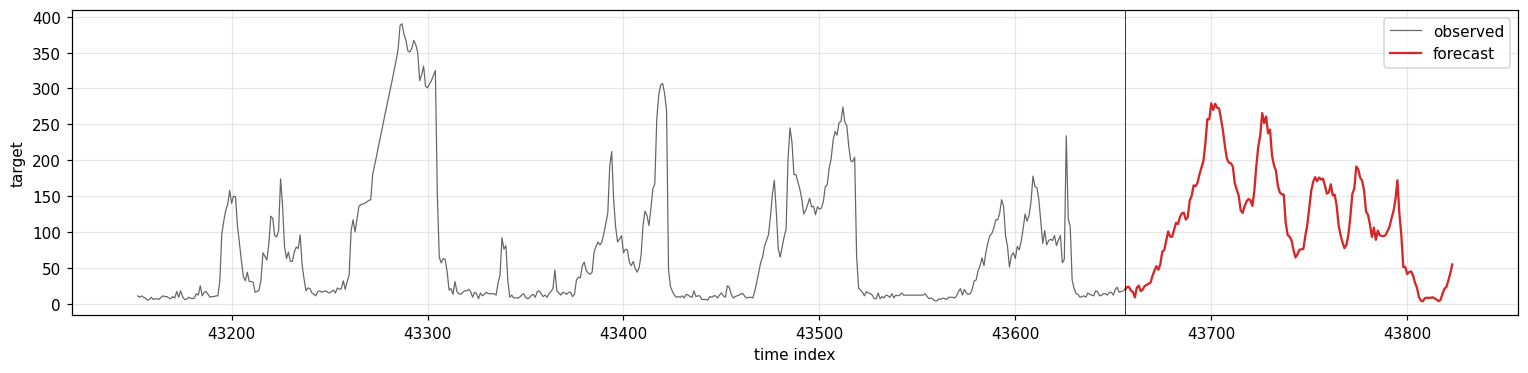

saved final/figures/fig03_final_forecast.pdf


In [18]:
es_final = np.array([N - H * k for k in range(N_ES, 0, -1)])
fcs, P_total, E_total = [], 0, 0
for s_ in SEEDS:
    model, b, to_raw, info = train_model(cfg_of(FINAL_RECIPE), s_, int(es_final[0]), es_final, verbose=False)
    fcs.append(predict(model, b, to_raw, np.array([N]))[0])
    P_total += info["P"]; E_total += info["epochs_run"]
    print(f"seed {s_}: P = {info['P']}, epochs = {info['epochs_run']}")
forecast = np.mean(fcs, 0)
assert forecast.shape == (H,) and np.isfinite(forecast).all() and (forecast >= 0).all()
submission = ", ".join(f"{v:.4f}" for v in forecast)
open(os.path.join(OUT, "submission.txt"), "w").write(submission)
pd.DataFrame({"time_idx": np.arange(N + 1, NT + 1), "value": forecast}).to_csv(os.path.join(OUT, "student_test_forecast.csv"), index=False)
json.dump({"P": P_total, "E": E_total}, open(os.path.join(OUT, "declared_P_E.json"), "w"))
print(f"P = {P_total}, E = {E_total}")
print(submission)
plt.figure(figsize=(14, 3.5))
plt.plot(np.arange(N - 3 * H, N), y[-3 * H:], color="0.4", lw=0.8, label="observed")
plt.plot(np.arange(N, NT), forecast, color="C3", label="forecast")
plt.axvline(N, color="k", lw=0.5); plt.legend(); plt.xlabel("time index"); plt.ylabel("target")
savefig("final_forecast")